In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv(r"C:\Users\raviteja\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.dropna()
df = df.drop('customerID', axis=1)
df['Churn'] = df['Churn'].map({'Yes':1, 'No':0})

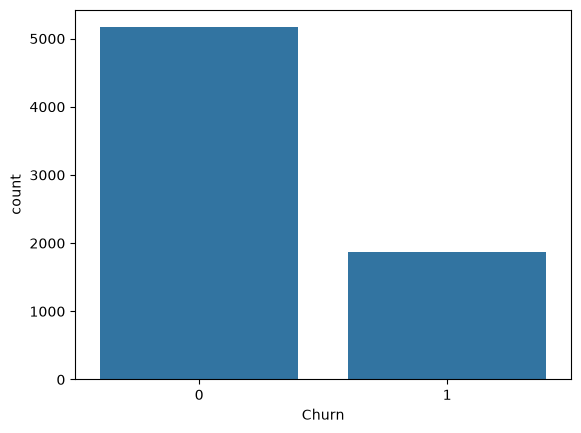

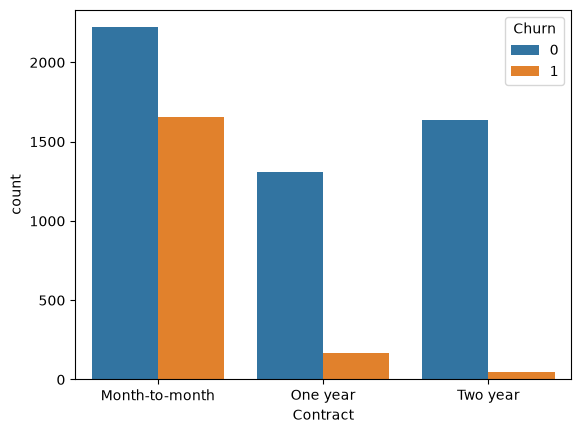

In [6]:

sns.countplot(data=df, x='Churn')
plt.show()

sns.countplot(data=df, x='Contract', hue='Churn')
plt.show()

In [7]:

df = pd.get_dummies(df, drop_first=True)


X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [8]:

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.52      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [9]:

from xgboost import XGBClassifier

xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
print(classification_report(y_test, y_pred_xgb))

C:\Users\raviteja\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:35:09] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

           0       0.82      0.87      0.85      1033
           1       0.58      0.48      0.52       374

    accuracy                           0.77      1407
   macro avg       0.70      0.68      0.68      1407
weighted avg       0.76      0.77      0.76      1407



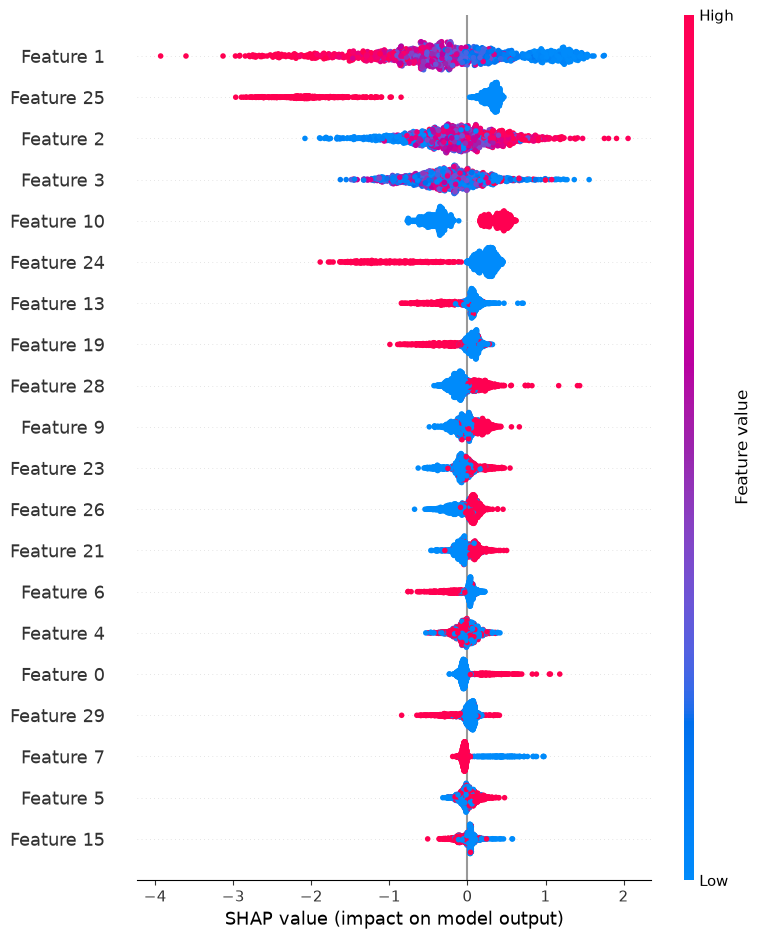

In [10]:

import shap

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)


shap.summary_plot(shap_values, X_test)

In [11]:

import joblib
joblib.dump(xgb, 'churn_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Saved!")

Saved!


In [1]:
%%writefile app.py
import streamlit as st

st.title("Customer Churn Prediction")
st.write("Month-to-Month customer")

tenure = st.slider("Tenure (Months)", 0, 72, 10)
monthly = st.number_input("Monthly Charges", 20, 120, 70)
contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])

if st.button("Predict"):
    if contract == "Month-to-month" and tenure < 12:
        st.error("HIGH RISK - Customer will Churn! Give Offer!")
    else:
        st.success("LOW RISK - Customer will Stay")

Writing app.py


In [ ]:

!streamlit run app.py